# Modelling SOH under unseen conditions

This notebook carries out the four "next steps" from the end of `02_eda_feature_discovery.ipynb`:

1. Drop the **LEAKY** group.
2. Reduce each redundancy block to one representative (best within-cell ρ).
3. Evaluate every model in three settings (random split, leave-cell-out, leave-profile-out), **with and without** the
   partial-capacity health indicators.
4. Fit imputation, scaling and feature selection **inside** each CV fold.

Reusable code is in [`src/modelling.py`](../src/modelling.py).

### How the data points are compared to pick features

Each row is one RTP@25 °C of one cell. The comparisons are done at three levels:

| Comparison | Question it answers | Where |
|---|---|---|
| Feature vs. SOH **inside one cell** (Spearman ρ over that cell's RTPs, median over cells) | Does the feature track *this cell's* ageing? | `within_cell_spearman` |
| Sign of that ρ **across cells** | Does it move in the same direction for every operating profile? | `sign_consistency` |
| Feature vs. feature over **all rows** (\|Spearman ρ\|) | Are two features the same information in disguise? | `redundancy_blocks` |

Spearman (rank) correlation is used instead of Pearson because many health indicators are monotone but non-linear in SOH.
The within-cell comparison matters most. Pooled correlation can look strong just because some profiles degrade faster
than others, and that does not help predict an unseen cell.

In [1]:
from pathlib import Path
import sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.modelling import (GROUPS, LEAKY, PARTIAL_CAPACITY, RedundancyPruner, rank_features,
                           redundancy_blocks, evaluate)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

df_all = pd.read_csv(ROOT / "results" / "rtp_features.csv", dtype={"cell_id": str})
df = df_all[df_all.rtp_T_set == 25].dropna(subset=["SOH"]).reset_index(drop=True)
print(df.shape, "|", df.cell_id.nunique(), "cells |", df.profile.nunique(), "profiles")

(306, 75) | 15 cells | 14 profiles


## Step 1: drop the leaky group

`cap_1C_Ah`, `dis1C_energy_Wh`, `cap_1C_spread_Ah` and `cap_ref_Ah` are the target itself, or the numerator and denominator of it.
They are never passed to any model.

In [ ]:
group_of = {c: g for g, cols in GROUPS.items() for c in cols}
audit = pd.read_csv(ROOT / "docs" / "feature_timing_audit.csv")
BEFORE_RTP = "before this RTP (usage history / profile)"
IN_RTP = "in this RTP, outside the target discharge"
TARGET_DIS = "inside the target 1C discharge or its rest (comparison only)"
in_df = lambda names: [c for c in names if c in df.columns]
MAIN_FEATS = in_df(audit.loc[audit.timing_group.isin([BEFORE_RTP, IN_RTP]), "feature"])
SAME_TEST_FEATS = in_df(audit.loc[audit.timing_group == TARGET_DIS, "feature"])
assert not set(LEAKY) & set(MAIN_FEATS + SAME_TEST_FEATS)
assert not set(MAIN_FEATS) & set(SAME_TEST_FEATS)

CYCLE_ONLY_FEATS = ["cum_EFC"]
FEATURE_SETS = {"Main (no same-test features)": MAIN_FEATS,
                "Comparison (with same-test features)": MAIN_FEATS + SAME_TEST_FEATS,
                "Cycle count only": CYCLE_ONLY_FEATS}
for k, v in FEATURE_SETS.items():
    print(f"{k:40s} {len(v)} candidate features")
print("same-test features:", SAME_TEST_FEATS)

`chg_CC_V0` is placed in the "without" ablation together with the partial-capacity group, because it is the rested
voltage right after a full discharge to 2.5 V. As noted in notebook 02, Section 7b, it works as a capacity proxy.

## Step 2: one representative per redundancy block

**Block definition:** features are clustered with complete linkage on distance `1 − |ρ|`. The tree is cut at 0.05, so
**every pair** inside a block has |ρ| ≥ 0.95. Each block keeps the feature with the highest score

`score = |median within-cell ρ| × sign consistency`

with ties broken by pooled |ρ|. Profile-design features are constant within a cell and so have no within-cell ρ. They fall back to
½·|pooled ρ|, which means a feature that actually tracks ageing wins a tie against them.

The table below is computed on **all** labelled rows. It is a description for the report only. For evaluation the same
choice is re-made on the training rows of every fold (Step 4).

In [3]:
def block_table(feats):
    p = RedundancyPruner(feats).fit(df[feats + ["cell_id"]], df.SOH.values)
    t = p.ranking_.join(p.blocks_)
    t["group"] = t.index.map(group_of)
    t["kept"] = t.index.isin(p.selected_)
    sizes = t.groupby("block").size()
    multi = t[t.block.map(sizes) > 1].sort_values(["block", "score"], ascending=[True, False])
    return p, multi[["block", "group", "within_rho", "sign_consistency", "pooled_rho", "score", "kept"]]

prunes = {}
for name, feats in FEATURE_SETS.items():
    p, multi = block_table(feats)
    prunes[name] = p
    print(f"\n### {name}: {len(feats)} -> {len(p.selected_)} features, "
          f"{multi.block.nunique()} multi-member blocks")
    display(multi.round(3))


### With partial-capacity HIs: 49 -> 33 features, 7 multi-member blocks


,block,group,within_rho,sign_consistency,pooled_rho,score,kept
prev_lp_T_mean,1,Previous load period,0.314,0.867,0.250,0.273,True
cum_lp_T_mean,1,Usage history,-0.306,0.667,0.281,0.204,False
lp_T_set,1,Profile design,NaN,NaN,0.365,0.183,False
dis1C_meanV,5,Shape / resistance HI,0.994,1.000,0.934,0.994,True
dis1C_t_to_3.6V_s,5,Partial-capacity HI,0.991,1.000,0.954,0.991,False
R_0p18C_10s_mean,5,Shape / resistance HI,-0.984,1.000,0.929,0.984,False
R_1p35C_10s_mean,5,Shape / resistance HI,-0.983,1.000,0.934,0.983,False
dis_C3_CC_Ah,5,Partial-capacity HI,0.983,1.000,0.937,0.983,False
R_1p13C_10s_mean,5,Shape / resistance HI,-0.983,1.000,0.933,0.983,False
R_1p13C_10s_soc55,5,Shape / resistance HI,-0.983,1.000,0.939,0.983,False



### Without partial-capacity HIs: 41 -> 30 features, 6 multi-member blocks


,block,group,within_rho,sign_consistency,pooled_rho,score,kept
prev_lp_T_mean,1,Previous load period,0.314,0.867,0.250,0.273,True
cum_lp_T_mean,1,Usage history,-0.306,0.667,0.281,0.204,False
lp_T_set,1,Profile design,NaN,NaN,0.365,0.183,False
R_0p18C_10s_mean,5,Shape / resistance HI,-0.984,1.000,0.929,0.984,True
R_1p13C_10s_mean,5,Shape / resistance HI,-0.983,1.000,0.933,0.983,False
R_1p35C_10s_mean,5,Shape / resistance HI,-0.983,1.000,0.934,0.983,False
R_1p13C_10s_soc55,5,Shape / resistance HI,-0.983,1.000,0.939,0.983,False
R_1p13C_10s_lowSOC,5,Shape / resistance HI,-0.968,1.000,0.898,0.968,False
R_1p13C_inst_mean,5,Shape / resistance HI,-0.960,1.000,0.919,0.960,False
dis1C_meanV,6,Shape / resistance HI,0.994,1.000,0.934,0.994,True


In [4]:
for name, p in prunes.items():
    kept = pd.Series(p.selected_).map(group_of).value_counts()
    print(f"{name}: kept per group\n{kept.to_string()}\n")

With partial-capacity HIs: kept per group
Shape / resistance HI    12
Previous load period      9
Profile design            6
Partial-capacity HI       3
Usage history             3

Without partial-capacity HIs: kept per group
Shape / resistance HI    12
Previous load period      9
Profile design            6
Usage history             3



## Steps 3 and 4: evaluation grid

* **Random split:** 5-fold shuffled KFold over rows. Neighbouring RTPs of the same cell end up in train and test, so this is the optimistic number.
* **Leave-cell-out:** `LeaveOneGroupOut` on `cell_id` (15 folds). Asks whether the model works on a cell it has never seen.
* **Leave-profile-out:** `LeaveOneGroupOut` on `profile` (14 folds; both L03 cells are held out together). Asks whether the model works under an operating profile it has never seen.

Each fold fits `RedundancyPruner → SimpleImputer(median) → [StandardScaler] → model` on the training rows only.
Pruning, imputation medians and scaling are therefore all learned without the held-out cell or profile.
Metrics are computed on the pooled out-of-fold predictions, so every row is predicted exactly once.

Models: training-mean baseline, Ridge (α chosen by internal CV), SVR-RBF (on a standardised target), random forest,
and histogram gradient boosting. Hyper-parameters are fixed, not tuned, so the comparison between settings is fair.
Nested group-aware tuning would be the next refinement.

In [ ]:
metrics, preds, picks = evaluate(df, FEATURE_SETS)
metrics.to_csv(ROOT / "results" / "model_comparison_timing.csv", index=False)
preds.to_csv(ROOT / "results" / "oof_predictions_timing.csv", index=False)

SPLITS = ["Random split", "Leave-cell-out", "Leave-profile-out"]
tbl = (metrics.pivot_table(index=["feature_set", "model"], columns="split", values=["MAE", "R2"])
             .reindex(columns=SPLITS, level=1))
display(tbl.round(2))

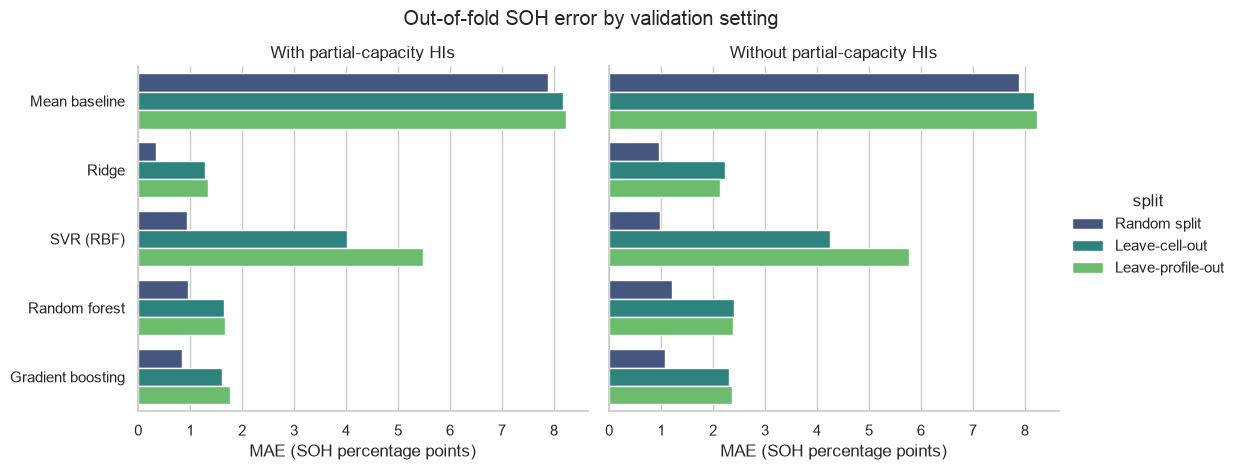

In [6]:
MODELS = ["Mean baseline", "Ridge", "SVR (RBF)", "Random forest", "Gradient boosting"]
g = sns.catplot(data=metrics, x="MAE", y="model", hue="split", col="feature_set", kind="bar",
                order=MODELS, hue_order=SPLITS, height=4.5, aspect=1.25, palette="viridis")
g.set_titles("{col_name}"); g.set_axis_labels("MAE (SOH percentage points)", "")
g.fig.suptitle("Out-of-fold SOH error by validation setting", y=1.04)
g.savefig(FIG / "model_comparison_mae.png", dpi=150, bbox_inches="tight"); plt.show()

### How much does accuracy depend on measuring capacity indirectly?

The table below shows, for each model and setting, the MAE without partial-capacity HIs minus the MAE with them (positive = worse without).

In [ ]:
mae = metrics.pivot_table(index=["model", "split"], columns="feature_set", values="MAE")
delta = (mae["Main (no same-test features)"] - mae["Comparison (with same-test features)"]).unstack("split")[SPLITS]
display(delta.reindex(MODELS).round(2))

### Generalisation gap

The gap is the MAE of the unseen-cell or unseen-profile setting minus the MAE of the random split. A large gap means the random-split score mostly reflects
memorising each cell's trajectory.

In [8]:
m = metrics.pivot_table(index=["feature_set", "model"], columns="split", values="MAE")
gap = pd.DataFrame({"cell gap": m["Leave-cell-out"] - m["Random split"],
                    "profile gap": m["Leave-profile-out"] - m["Random split"]})
display(gap.round(2))

cell gap  profile gap
feature_set                  model                                   
With partial-capacity HIs    Gradient boosting      0.78         0.93
                             Mean baseline          0.30         0.36
                             Random forest          0.69         0.72
                             Ridge                  0.96         1.00
                             SVR (RBF)              3.07         4.53
Without partial-capacity HIs Gradient boosting      1.23         1.30
                             Mean baseline          0.30         0.36
                             Random forest          1.19         1.19
                             Ridge                  1.27         1.18
                             SVR (RBF)              3.27         4.80

## Which held-out profiles are hard?

Per-profile MAE under leave-profile-out for the best model of each feature set. Notebook 02, Section 8 says to expect
profiles at the edge of the operating range (e.g. 45 °C / 95 % SoC calendar ageing, or the deep-degraded L35 and V212) to be the worst.

In [ ]:
lpo = metrics[metrics.split == "Leave-profile-out"]
best = lpo.loc[lpo.groupby("feature_set").MAE.idxmin(), ["feature_set", "model"]]
print(best.to_string(index=False))
sub = preds.merge(best, on=["feature_set", "model"])
sub = sub[sub.split == "Leave-profile-out"].assign(abs_err=lambda d: (d.y_pred - d.y_true).abs())
per_prof = sub.pivot_table(index="profile", columns="feature_set", values="abs_err", aggfunc="mean")
per_prof.columns = [f"MAE {c}" for c in per_prof.columns]
cond = df.groupby("profile").agg(SOH_min=("SOH", "min"), T=("lp_T_set", "first"), SoC=("lp_SoC", "first"),
                                 dSoC=("lp_dSoC", "first"), ADC=("lp_ADC", "first"))
MAIN_COL = "MAE Main (no same-test features)"
display(per_prof.join(cond).sort_values(MAIN_COL, ascending=False).round(2))

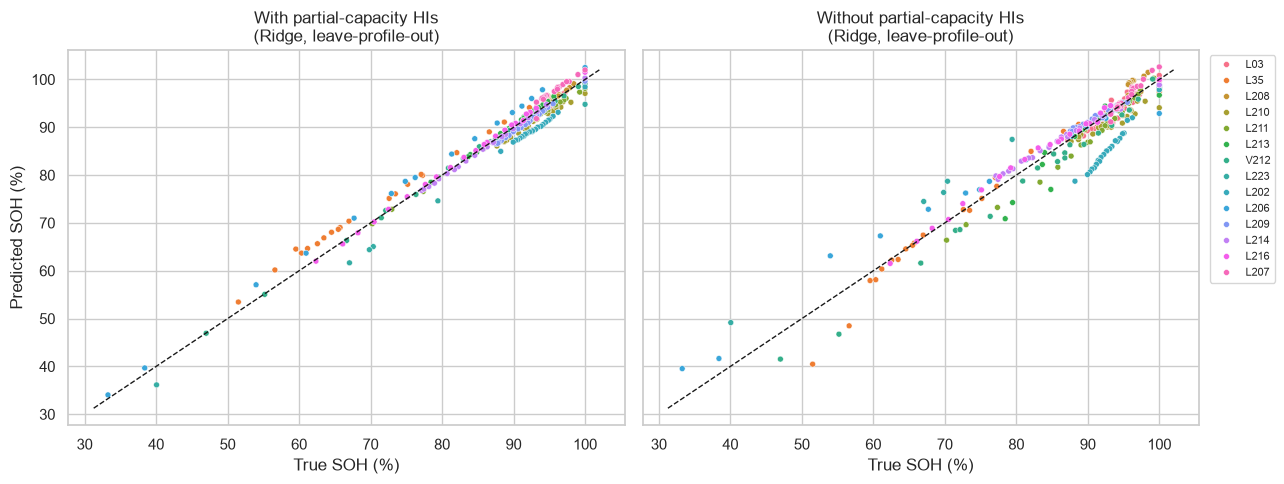

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, (fs, d) in zip(axes, sub.groupby("feature_set")):
    sns.scatterplot(data=d, x="y_true", y="y_pred", hue="profile", s=18, ax=ax, legend=(ax is axes[-1]))
    lim = [d[["y_true", "y_pred"]].min().min() - 2, 102]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set(title=f"{fs}\n({d.model.iloc[0]}, leave-profile-out)", xlabel="True SOH (%)", ylabel="Predicted SOH (%)")
axes[-1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "pred_vs_true_leave_profile_out.png", dpi=150); plt.show()

## Step 4 check: is the in-fold feature selection stable?

If the pruner keeps the same representatives in nearly every fold, the Step 2 table is a fair summary of the model's
inputs. Features chosen in only a few folds are near-ties inside their block.

In [11]:
for fs in FEATURE_SETS:
    pk = picks[(picks.feature_set == fs) & (picks.split != "Random split")]
    freq = pd.Series([c for s in pk.selected for c in s]).value_counts() / len(pk)
    unstable = freq[freq < 0.9]
    print(f"{fs}: {len(freq)} features ever selected over {len(pk)} group folds; "
          f"selected in every fold: {(freq == 1).sum()}")
    if len(unstable):
        print("  selected in <90% of folds:", unstable.round(2).to_dict())

With partial-capacity HIs: 41 features ever selected over 29 group folds; selected in every fold: 26
  selected in <90% of folds: {'ica_p1_height': 0.86, 'cum_EFC': 0.86, 'days_since_start': 0.83, 'chg_CC_Ah': 0.55, 'chg_CC_time_s': 0.45, 'R_0p18C_10s_mean': 0.41, 'prev_lp_I_dis_mean': 0.24, 'rtp_index': 0.17, 'cum_dis_Ah': 0.14, 'dis1C_t_to_3.6V_s': 0.07, 'R_1p13C_10s_lowSOC': 0.07, 'lp_T_set': 0.03}
Without partial-capacity HIs: 35 features ever selected over 29 group folds; selected in every fold: 26
  selected in <90% of folds: {'days_since_start': 0.76, 'R_0p18C_10s_mean': 0.69, 'ica_p1_height': 0.31, 'prev_lp_I_dis_mean': 0.24, 'rtp_index': 0.24, 'cum_dis_Ah': 0.07, 'lp_T_set': 0.03}


## Interpolation vs. extrapolation profiles

Each profile is labelled from its design settings only, before looking at any results. A profile is extrapolation if one of its design settings is outside the range of the other profiles. Otherwise it is interpolation. V212 has no design settings in the code, so it is unclassified.

In [ ]:
DESIGN = ["lp_T_set", "lp_CC", "lp_ADC", "lp_PDC", "lp_F", "lp_SoC", "lp_dSoC"]
prof_design = df.groupby("profile")[DESIGN].first()

def regime(p):
    if prof_design.loc[p].isna().any():
        return "unclassified"
    others = prof_design.drop(p)
    outside = (prof_design.loc[p] < others.min()) | (prof_design.loc[p] > others.max())
    return "extrapolation" if outside.any() else "interpolation"

REGIME = {p: regime(p) for p in prof_design.index}
print(pd.Series(REGIME).value_counts().to_string())
print("extrapolation:", [p for p, r in REGIME.items() if r == "extrapolation"])
print("unclassified:", [p for p, r in REGIME.items() if r == "unclassified"])

In [ ]:
lpo = preds[preds.split == "Leave-profile-out"].copy()
lpo["regime"] = lpo.profile.map(REGIME)
lpo["abs_err"] = (lpo.y_pred - lpo.y_true).abs()
regime_tbl = (lpo.groupby(["feature_set", "model", "regime"])
                 .agg(MAE=("abs_err", "mean"), n_rows=("abs_err", "size"),
                      n_cells=("cell_id", "nunique"), n_profiles=("profile", "nunique"))
                 .reset_index())
regime_tbl.to_csv(ROOT / "results" / "profile_regime_timing.csv", index=False)
display(regime_tbl.pivot_table(index=["feature_set", "model"], columns="regime",
                               values=["MAE", "n_cells"]).round(2))

## Summary

**Feature reduction (Steps 1–2).** Removing the leaky group leaves 49 candidates (41 without the partial-capacity HIs).
Merging |ρ| ≥ 0.95 blocks brings this to **33 / 30** features. The biggest block is the whole resistance family
(`R_*`), which collapses to one feature: `R_0p18C_10s_mean` when partial-capacity HIs are excluded, and `dis1C_meanV` when they are included, because they
also fall in that block. Throughput (`cum_EFC`≈`cum_dis_Ah`) and time (`days_since_start`≈`rtp_index`) each keep one.
Inside the folds, 26 features are picked in every fold. The unstable picks are near-ties within a block (e.g. `chg_CC_Ah` vs
`chg_CC_time_s`, ρ = 1.00), so the choice between them does not matter.

**Validation setting (Step 3).** A random split under-states error by a factor of 2–4. Ridge reaches 0.34 pp MAE on a random split
but 1.30 pp on unseen cells. Leave-profile-out is only slightly harder than leave-cell-out on average, because most cells have their
own profile, so the two settings largely overlap here. The per-profile table is the more informative view.

**Dependence on indirect capacity measurement.** Dropping the partial-capacity HIs raises unseen-cell / unseen-profile
MAE by about 0.6–0.9 pp (Ridge: 1.30 → 2.23 leave-cell-out, 1.34 → 2.14 leave-profile-out). R² stays around 0.9 without them, so
resistance and curve-shape HIs carry most of the signal.

**Models.** Ridge is best in every setting. RF and gradient boosting come close, and SVR-RBF generalises poorly
(it cannot extrapolate beyond the training range). These hyper-parameters are fixed, not tuned.

**Where it breaks.** The worst held-out profiles are the edge cases from notebook 02 §8. **L202** (45 °C, 15 % SoC
calendar ageing, almost no SOH change) reaches 7.4 pp MAE without partial-capacity HIs, and **L223** (only 6 RTPs, down to 40 % SOH)
reaches 6.8 pp. Both sit outside the training distribution. These are the "when does performance decrease" cases.

**Note:** The summary above describes the earlier version of this notebook. The current results are in `results/modelling_capacity_excluded/` (main results) and `results/modelling_tuned/` (tuned models). The main feature set leaves out features measured inside the target 1C discharge and five capacity measures, and Ridge's alpha is chosen with splits by cell inside each training fold.